# RQ15 — Representation × positive–unlabeled learning paradigm

## Scientific question

**Does the value and behavior of positive–unlabeled learning depend on how proteins are represented?**

The central interaction is not a representation leaderboard and not a PU-method leaderboard.

For a dedicated PU method \(m\), define its gain over naive P-vs-U within the same frozen benchmark cell:

\[
G_m(r)
=
M_{m,r}
-
M_{\mathrm{naive},r}
\]

where \(r\) is the protein representation.

RQ15 asks whether:

\[
G_m(r_2)-G_m(r_1)
\neq 0
\]

for representation pairs such as:

\[
\mathrm{T30}-\mathrm{T6}
\]

or:

\[
\mathrm{T30}-\mathrm{Roxy}.
\]

This is an **effect-of-effect**:

> Does changing the representation alter the consequence of changing the learning paradigm?

Operational note: the original conceptual roadmap numbered this question RQ16, but the frozen notebook roadmap places **Representation × PU paradigm** in notebook **15** because the conservative-vs-broad analysis was implemented as notebook 14.


## Main hypotheses to test

RQ15 explicitly distinguishes two plausible regimes.

### Representation substitutes for PU

A stronger representation may organize P/U structure so well that dedicated PU learning adds progressively less:

\[
G_{\mathrm{PU}}(\mathrm{T30})
<
G_{\mathrm{PU}}(\mathrm{Roxy})
\]

or candidate rankings across paradigms become more similar under T30.

### Representation enables PU

A richer representation may expose meaningful structure inside U that a PU-specific learner can exploit:

\[
G_{\mathrm{PU}}(\mathrm{T30})
>
G_{\mathrm{PU}}(\mathrm{Roxy})
\]

or BaggingPU may increasingly reorganize the candidate tail under stronger representations.

Both outcomes are scientifically informative.

The analysis must therefore treat **recognition of known positives** and **candidate prioritization inside U** as separate outcomes.


## Statistical / comparison contract

All PU-method comparisons within the same:

`task × R × S × representation × base learner`

are **paired benchmark-cell contrasts**, because the methods score the same frozen native outer-test entities.

All representation comparisons within the same:

`task × R × S × PU method × base learner`

are also matched benchmark-cell contrasts.

The two-way interaction is therefore evaluated descriptively as a **difference of matched differences**.

RQ15 does **not** perform finite-test bootstrap inference; that remains RQ17.

`U` means **unlabeled**, never confirmed negative.

Primary recognition diagnostic:

\[
\mathrm{Recovery}_{U95}
=
\Pr(s_P \ge Q_{0.95}(s_U))
\]

Supporting recognition diagnostics:

- median P percentile relative to U;
- U90 recovery;
- U99 recovery;
- strict U99 only as a tie-resolution diagnostic.

Candidate-space diagnostics:

- U-score Spearman agreement across paradigms;
- tie-aware top-1% overlap;
- tie-aware top-5% overlap;
- BaggingPU internal score variability.

Elkan–Noto U99 is never interpreted without its clipping/tie context.


## Scope boundary

RQ15 **does** analyze:

- PU gain conditioned on representation;
- representation gain conditioned on PU paradigm;
- two-way effect-of-effect interactions;
- whether those interactions change across R/S regimes;
- whether representation changes candidate-ranking agreement between PU paradigms;
- whether representation changes BaggingPU internal stability;
- as a secondary RQ14 bridge, whether representation changes how PU methods prioritize `U_other_unresolved` inside broad U.

RQ15 does **not** re-open:

- the overall PU-method conclusion → RQ12;
- the main R/S PU landscape → RQ13;
- the main conservative-vs-broad conclusion → RQ14;
- common-test R/S decomposition → RQ16;
- bootstrap uncertainty → RQ17;
- runtime/compute → RQ18.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 280)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASKS = ["pu_conservative", "pu_broad"]
METHODS = ["naive", "baggingpu", "elkan_noto"]
DEDICATED_METHODS = ["baggingpu", "elkan_noto"]

REPRESENTATIONS = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_LABELS = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

METHOD_LABELS = {
    "naive": "Naive P-vs-U",
    "baggingpu": "BaggingPU",
    "elkan_noto": "Elkan–Noto",
}

ALGORITHMS = ["LR", "XGB"]

PRIMARY = "fraction_P_above_U95"

RECOGNITION_METRICS = [
    "fraction_P_above_U90",
    "fraction_P_above_U95",
    "fraction_P_above_U99",
    "fraction_P_strictly_above_U99",
    "median_P_percentile_vs_U",
]

PRACTICAL_TIE = 0.02

REP_CONTRASTS = [
    ("roxy_48", "onehot_1024"),
    ("roxy_48", "esm2_t6_8m"),
    ("roxy_48", "esm2_t30_150m"),
    ("onehot_1024", "esm2_t6_8m"),
    ("onehot_1024", "esm2_t30_150m"),
    ("esm2_t6_8m", "esm2_t30_150m"),
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_pu/stage12b2").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12B2 and Stage12A PU outputs."
    )

ROOT = find_project_root()
PU_DIR = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
CACHE_DIR = ROOT / "results/analysis_pu/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("PU_DIR:", PU_DIR)
print("CACHE_DIR:", CACHE_DIR)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
PU_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/stage12b2
CACHE_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache


# 1. Validate the frozen PU benchmark


In [2]:
manifest_path = PU_DIR / "stage12b2_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

manifest = json.loads(manifest_path.read_text())

if manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Stage12B2 status is {manifest.get('status')}; RQ15 requires PASS."
    )

registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

required_registry = {
    "experiment_id",
    "task",
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    "path",
}
missing = required_registry - set(registry.columns)
if missing:
    raise KeyError(f"Registry missing columns: {sorted(missing)}")

assert len(registry) == 768
assert set(registry["task"]) == set(TASKS)
assert set(registry["method"]) == set(METHODS)
assert set(registry["representation"]) == set(REPRESENTATIONS)
assert set(registry["algorithm"]) == set(ALGORITHMS)

coverage = (
    registry.groupby(
        [
            "task", "R", "S",
            "representation", "method", "algorithm",
        ]
    )
    .size()
)

assert len(coverage) == 768
assert coverage.eq(1).all()

print("PASS — frozen PU factorial is complete.")
display(
    registry.groupby(
        ["task", "representation", "method"]
    ).size().unstack("method")
)


PASS — frozen PU factorial is complete.


method                          baggingpu  elkan_noto  naive
task            representation                              
pu_broad        esm2_t30_150m          32          32     32
                esm2_t6_8m             32          32     32
                onehot_1024            32          32     32
                roxy_48                32          32     32
pu_conservative esm2_t30_150m          32          32     32
                esm2_t6_8m             32          32     32
                onehot_1024            32          32     32
                roxy_48                32          32     32

# 2. Load corrected PU-native diagnostics


In [3]:
NATIVE_PATH = CACHE_DIR / "rq12_pu_native_score_diagnostics.tsv"

def detect_score_col(df):
    for c in [
        "score_positive",
        "score",
        "corrected_score",
        "probability",
    ]:
        if c in df.columns:
            return c
    raise KeyError(f"No score column found; columns={list(df.columns)}")

def percentile_against(values, reference):
    values = np.asarray(values, dtype=float)
    reference = np.sort(np.asarray(reference, dtype=float))
    if len(reference) == 0:
        return np.full(len(values), np.nan)
    return np.searchsorted(reference, values, side="right") / len(reference)

def rebuild_native():
    rows = []

    for rec in registry.itertuples(index=False):
        score_path = Path(rec.path) / "outer_test_scores.parquet"
        if not score_path.is_file():
            raise FileNotFoundError(score_path)

        df = pd.read_parquet(score_path)

        if "observed_role" not in df.columns:
            raise KeyError(f"{score_path}: missing observed_role")

        score_col = detect_score_col(df)
        roles = df["observed_role"].astype(str).str.upper()
        score = pd.to_numeric(df[score_col], errors="coerce")

        P = score[roles.eq("P")].dropna().to_numpy(float)
        U = score[roles.eq("U")].dropna().to_numpy(float)

        if len(P) == 0 or len(U) == 0:
            raise RuntimeError(
                f"{rec.experiment_id}: nP={len(P)}, nU={len(U)}"
            )

        q90, q95, q99 = np.quantile(U, [0.90, 0.95, 0.99])
        p_pct = percentile_against(P, U)

        rows.append({
            "experiment_id": rec.experiment_id,
            "task": rec.task,
            "R": int(rec.R),
            "S": int(rec.S),
            "representation": rec.representation,
            "method": rec.method,
            "algorithm": rec.algorithm,
            "n_P_test": len(P),
            "n_U_test": len(U),
            "fraction_P_above_U90": float(np.mean(P >= q90)),
            "fraction_P_above_U95": float(np.mean(P >= q95)),
            "fraction_P_above_U99": float(np.mean(P >= q99)),
            "fraction_P_strictly_above_U99": float(np.mean(P > q99)),
            "median_P_percentile_vs_U": float(np.median(p_pct)),
            "U_q99": float(q99),
            "U_fraction_at_score_1": float(
                np.mean(np.isclose(U, 1.0, rtol=0.0, atol=1e-12))
            ),
            "P_fraction_at_score_1": float(
                np.mean(np.isclose(P, 1.0, rtol=0.0, atol=1e-12))
            ),
        })

    return pd.DataFrame(rows)

if NATIVE_PATH.is_file():
    native = pd.read_csv(NATIVE_PATH, sep="\t", low_memory=False)
    native_source = "RQ12 corrected cache"
else:
    native = rebuild_native()
    native_source = "reconstructed from frozen outer-test scores"

assert len(native) == 768

required_native = {
    "task", "R", "S", "representation", "method", "algorithm",
    *RECOGNITION_METRICS,
}
missing = required_native - set(native.columns)
if missing:
    raise KeyError(f"Native diagnostics missing: {sorted(missing)}")

print("Native source:", native_source)
display(
    native.groupby(["representation", "method"])[PRIMARY]
    .median()
    .unstack("method")
    .reindex(REPRESENTATIONS)
)


Native source: RQ12 corrected cache


method,baggingpu,elkan_noto,naive
representation,,,
roxy_48,0.711087,0.709283,0.709283
onehot_1024,0.567202,0.492872,0.453590
esm2_t6_8m,0.849337,0.852265,0.852265
esm2_t30_150m,0.930716,0.930459,0.930459


# 3. Recognition baseline by representation × learning paradigm


In [4]:
recognition_summary = (
    native.groupby(["representation", "method"])
    .agg(
        n=(PRIMARY, "size"),
        median_U95=(PRIMARY, "median"),
        mean_U95=(PRIMARY, "mean"),
        q25_U95=(PRIMARY, lambda x: x.quantile(0.25)),
        q75_U95=(PRIMARY, lambda x: x.quantile(0.75)),
        median_P_percentile=("median_P_percentile_vs_U", "median"),
        median_U90=("fraction_P_above_U90", "median"),
        median_U99=("fraction_P_above_U99", "median"),
        median_strict_U99=("fraction_P_strictly_above_U99", "median"),
    )
    .reset_index()
)

recognition_summary["representation"] = pd.Categorical(
    recognition_summary["representation"],
    categories=REPRESENTATIONS,
    ordered=True,
)

display(
    recognition_summary.sort_values(
        ["representation", "method"]
    )
)


,representation,method,n,median_U95,mean_U95,q25_U95,q75_U95,median_P_percentile,median_U90,median_U99,median_strict_U99
9,roxy_48,baggingpu,64,0.711087,0.707157,0.657787,0.757160,0.984425,0.820291,0.420692,0.420692
10,roxy_48,elkan_noto,64,0.709283,0.718374,0.668101,0.763945,1.000000,0.813804,0.650174,0.000000
11,roxy_48,naive,64,0.709283,0.706594,0.651523,0.763945,0.984310,0.813804,0.411125,0.411125
6,onehot_1024,baggingpu,64,0.567202,0.551597,0.479948,0.618236,0.962464,0.720728,0.222220,0.222220
7,onehot_1024,elkan_noto,64,0.492872,0.473574,0.370288,0.585301,0.938246,0.609604,0.487294,0.000000
8,onehot_1024,naive,64,0.453590,0.456489,0.370288,0.584498,0.935994,0.609604,0.196076,0.196076
3,esm2_t6_8m,baggingpu,64,0.849337,0.847400,0.823598,0.876171,0.996264,0.900488,0.671701,0.671701
4,esm2_t6_8m,elkan_noto,64,0.852265,0.851023,0.830242,0.880254,1.000000,0.901795,0.749423,0.293279
5,esm2_t6_8m,naive,64,0.852265,0.851023,0.830242,0.880254,0.996372,0.901795,0.678491,0.678491
0,esm2_t30_150m,baggingpu,64,0.930716,0.925083,0.909187,0.943052,0.999041,0.947846,0.860844,0.860844


This table is descriptive context only.

The central RQ15 quantity is not which representation or method has the largest U95 recovery. It is whether **the method effect changes when the representation changes**.


# 4. Dedicated-PU gain versus naive within each representation


In [5]:
GAIN_KEYS = [
    "task", "R", "S", "representation", "algorithm"
]

wide_methods = (
    native.pivot_table(
        index=GAIN_KEYS,
        columns="method",
        values=PRIMARY,
        aggfunc="first",
    )
    .reset_index()
)

if not set(METHODS) <= set(wide_methods.columns):
    raise RuntimeError("Incomplete PU method coverage in native table.")

gain_rows = []

for method in DEDICATED_METHODS:
    tmp = wide_methods[GAIN_KEYS].copy()
    tmp["method"] = method
    tmp["naive_value"] = wide_methods["naive"]
    tmp["method_value"] = wide_methods[method]
    tmp["gain_vs_naive"] = (
        wide_methods[method] - wide_methods["naive"]
    )
    gain_rows.append(tmp)

method_gain = pd.concat(gain_rows, ignore_index=True)

assert len(method_gain) == 512

gain_by_rep = (
    method_gain.groupby(["method", "representation"])
    ["gain_vs_naive"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= PRACTICAL_TIE).mean(),
    )
    .reset_index()
)

gain_by_rep["representation"] = pd.Categorical(
    gain_by_rep["representation"],
    categories=REPRESENTATIONS,
    ordered=True,
)

display(
    gain_by_rep.sort_values(
        ["method", "representation"]
    )
)


,method,representation,n,mean,median,q25,q75,median_abs,fraction_positive,fraction_negative,fraction_practical_tie
3,baggingpu,roxy_48,64,0.000563,0.000000,-0.004520,0.003812,0.004110,0.421875,0.468750,0.953125
2,baggingpu,onehot_1024,64,0.095108,0.093082,0.014960,0.167707,0.093082,0.828125,0.156250,0.265625
1,baggingpu,esm2_t6_8m,64,-0.003623,-0.002757,-0.010683,0.001997,0.006045,0.359375,0.625000,0.875000
0,baggingpu,esm2_t30_150m,64,0.001384,0.000344,-0.005438,0.005313,0.005442,0.500000,0.453125,0.953125
7,elkan_noto,roxy_48,64,0.011780,0.000000,0.000000,0.007187,0.000000,0.250000,0.000000,0.750000
6,elkan_noto,onehot_1024,64,0.017084,0.000000,0.000000,0.019179,0.000000,0.343750,0.000000,0.750000
5,elkan_noto,esm2_t6_8m,64,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
4,elkan_noto,esm2_t30_150m,64,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000


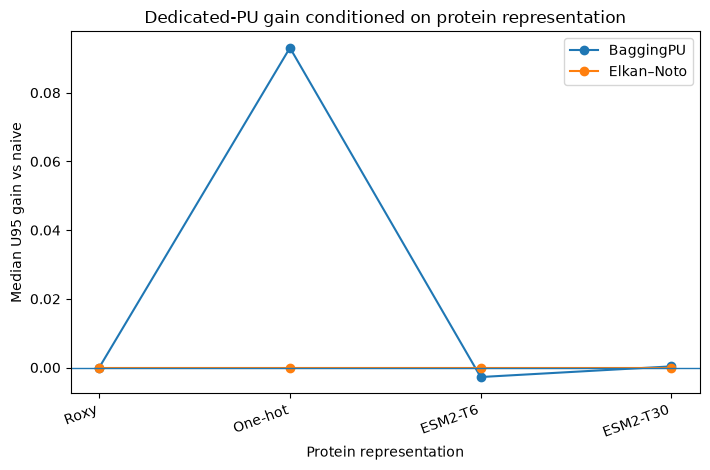

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))

for method in DEDICATED_METHODS:
    g = (
        gain_by_rep[gain_by_rep["method"].eq(method)]
        .sort_values("representation")
    )

    ax.plot(
        [REP_LABELS[str(x)] for x in g["representation"]],
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Protein representation")
ax.set_ylabel("Median U95 gain vs naive")
ax.set_title("Dedicated-PU gain conditioned on protein representation")
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# 5. Effect-of-effect: does PU gain change with representation quality?


In [7]:
interaction_rows = []

for method in DEDICATED_METHODS:
    g = method_gain[
        method_gain["method"].eq(method)
    ]

    wide = g.pivot_table(
        index=["task", "R", "S", "algorithm"],
        columns="representation",
        values="gain_vs_naive",
        aggfunc="first",
    ).reset_index()

    for rep_a, rep_b in REP_CONTRASTS:
        if rep_a not in wide.columns or rep_b not in wide.columns:
            raise RuntimeError(
                f"Missing representation contrast: {rep_a}, {rep_b}"
            )

        tmp = wide[
            ["task", "R", "S", "algorithm"]
        ].copy()

        tmp["method"] = method
        tmp["representation_A"] = rep_a
        tmp["representation_B"] = rep_b
        tmp["gain_A"] = wide[rep_a]
        tmp["gain_B"] = wide[rep_b]
        tmp["delta_PU_gain_B_minus_A"] = (
            wide[rep_b] - wide[rep_a]
        )

        interaction_rows.append(tmp)

rep_x_method_interaction = pd.concat(
    interaction_rows,
    ignore_index=True,
)

interaction_summary = (
    rep_x_method_interaction.groupby(
        ["method", "representation_A", "representation_B"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_practical_tie=lambda x: (
            x.abs() <= PRACTICAL_TIE
        ).mean(),
    )
    .reset_index()
)

interaction_summary["contrast"] = (
    interaction_summary["representation_B"].map(REP_LABELS)
    + " − "
    + interaction_summary["representation_A"].map(REP_LABELS)
)

display(
    interaction_summary[
        [
            "method", "contrast", "n", "mean", "median",
            "q25", "q75", "median_abs",
            "fraction_positive",
            "fraction_negative",
            "fraction_practical_tie",
        ]
    ]
)


,method,contrast,n,mean,median,q25,q75,median_abs,fraction_positive,fraction_negative,fraction_practical_tie
0,baggingpu,ESM2-T30 − ESM2-T6,64,0.005007,0.003970,-0.000165,0.008860,0.006370,0.703125,0.265625,0.890625
1,baggingpu,ESM2-T30 − One-hot,64,-0.093724,-0.096544,-0.162494,-0.021059,0.096544,0.093750,0.906250,0.218750
2,baggingpu,ESM2-T6 − One-hot,64,-0.098731,-0.099656,-0.170999,-0.020513,0.099656,0.078125,0.921875,0.234375
3,baggingpu,ESM2-T30 − Roxy,64,0.000821,0.002006,-0.006941,0.009680,0.007343,0.546875,0.437500,0.843750
4,baggingpu,ESM2-T6 − Roxy,64,-0.004186,-0.000340,-0.014057,0.004126,0.006237,0.484375,0.500000,0.828125
5,baggingpu,One-hot − Roxy,64,0.094545,0.091344,0.011695,0.170678,0.091344,0.890625,0.109375,0.281250
6,elkan_noto,ESM2-T30 − ESM2-T6,64,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
7,elkan_noto,ESM2-T30 − One-hot,64,-0.017084,0.000000,-0.019179,0.000000,0.000000,0.000000,0.343750,0.750000
8,elkan_noto,ESM2-T6 − One-hot,64,-0.017084,0.000000,-0.019179,0.000000,0.000000,0.000000,0.343750,0.750000
9,elkan_noto,ESM2-T30 − Roxy,64,-0.011780,0.000000,-0.007187,0.000000,0.000000,0.000000,0.250000,0.750000


Interpretation of:

\[
\Delta G_{\mathrm{PU}}
=
G_{\mathrm{PU}}(r_B)-G_{\mathrm{PU}}(r_A)
\]

- positive → dedicated PU becomes **more beneficial** under representation \(r_B\);
- negative → dedicated PU becomes **less beneficial** under \(r_B\);
- near zero → representation and PU paradigm are largely separable for U95 recovery.

The two contrasts of highest scientific interest are:

- `ESM2-T30 − Roxy`;
- `ESM2-T30 − ESM2-T6`.


# 6. Central T30 interaction contrasts by task and U-universe


In [8]:
central_interactions = rep_x_method_interaction[
    (
        rep_x_method_interaction["representation_A"].eq("roxy_48")
        & rep_x_method_interaction["representation_B"].eq("esm2_t30_150m")
    )
    |
    (
        rep_x_method_interaction["representation_A"].eq("esm2_t6_8m")
        & rep_x_method_interaction["representation_B"].eq("esm2_t30_150m")
    )
].copy()

central_interactions["contrast"] = (
    central_interactions["representation_B"].map(REP_LABELS)
    + " − "
    + central_interactions["representation_A"].map(REP_LABELS)
)

central_by_task = (
    central_interactions.groupby(
        ["method", "contrast", "task"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (
            x.abs() <= PRACTICAL_TIE
        ).mean(),
    )
    .reset_index()
)

display(central_by_task)


,method,contrast,task,n,mean,median,q25,q75,fraction_positive,fraction_practical_tie
0,baggingpu,ESM2-T30 − ESM2-T6,pu_broad,32,0.004993,0.003314,-8.416930e-04,0.009311,0.65625,0.87500
1,baggingpu,ESM2-T30 − ESM2-T6,pu_conservative,32,0.005021,0.004915,8.326673e-17,0.008791,0.75000,0.90625
2,baggingpu,ESM2-T30 − Roxy,pu_broad,32,0.001156,0.002006,-6.135162e-03,0.008336,0.56250,0.87500
3,baggingpu,ESM2-T30 − Roxy,pu_conservative,32,0.000485,0.001578,-6.940857e-03,0.009680,0.53125,0.81250
4,elkan_noto,ESM2-T30 − ESM2-T6,pu_broad,32,0.000000,0.000000,0.000000e+00,0.000000,0.00000,1.00000
5,elkan_noto,ESM2-T30 − ESM2-T6,pu_conservative,32,0.000000,0.000000,0.000000e+00,0.000000,0.00000,1.00000
6,elkan_noto,ESM2-T30 − Roxy,pu_broad,32,-0.023559,-0.014374,-4.810050e-02,0.000000,0.00000,0.50000
7,elkan_noto,ESM2-T30 − Roxy,pu_conservative,32,0.000000,0.000000,0.000000e+00,0.000000,0.00000,1.00000


# 7. Does the interaction depend on the downstream learner?


In [9]:
central_by_algorithm = (
    central_interactions.groupby(
        ["method", "contrast", "algorithm"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (
            x.abs() <= PRACTICAL_TIE
        ).mean(),
    )
    .reset_index()
)

display(central_by_algorithm)


,method,contrast,algorithm,n,mean,median,q25,q75,fraction_positive,fraction_practical_tie
0,baggingpu,ESM2-T30 − ESM2-T6,LR,32,0.005602,0.003619,0.000505,0.008414,0.75000,0.87500
1,baggingpu,ESM2-T30 − ESM2-T6,XGB,32,0.004413,0.004915,-0.001538,0.009729,0.65625,0.90625
2,baggingpu,ESM2-T30 − Roxy,LR,32,0.009243,0.008520,0.003034,0.014946,0.84375,0.84375
3,baggingpu,ESM2-T30 − Roxy,XGB,32,-0.007602,-0.006995,-0.012365,-0.000265,0.25000,0.84375
4,elkan_noto,ESM2-T30 − ESM2-T6,LR,32,0.000000,0.000000,0.000000,0.000000,0.00000,1.00000
5,elkan_noto,ESM2-T30 − ESM2-T6,XGB,32,0.000000,0.000000,0.000000,0.000000,0.00000,1.00000
6,elkan_noto,ESM2-T30 − Roxy,LR,32,-0.023559,-0.014374,-0.048100,0.000000,0.00000,0.50000
7,elkan_noto,ESM2-T30 − Roxy,XGB,32,0.000000,0.000000,0.000000,0.000000,0.00000,1.00000


# 8. R/S modulation of the representation × paradigm interaction


In [10]:
central_by_R = (
    central_interactions.groupby(
        ["method", "contrast", "R"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

central_by_S = (
    central_interactions.groupby(
        ["method", "contrast", "S"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(central_by_R)
display(central_by_S)


,method,contrast,R,n,mean,median,q25,q75
0,baggingpu,ESM2-T30 − ESM2-T6,30,16,0.008500,0.009248,-0.001556,0.021606
1,baggingpu,ESM2-T30 − ESM2-T6,50,16,0.005242,0.006211,-0.001390,0.009346
2,baggingpu,ESM2-T30 − ESM2-T6,70,16,0.005966,0.006610,0.002355,0.008791
3,baggingpu,ESM2-T30 − ESM2-T6,90,16,0.000321,0.000666,-0.000864,0.002887
4,baggingpu,ESM2-T30 − Roxy,30,16,-0.002051,-0.000041,-0.021249,0.017068
5,baggingpu,ESM2-T30 − Roxy,50,16,0.001469,-0.002090,-0.009696,0.010828
6,baggingpu,ESM2-T30 − Roxy,70,16,0.002880,0.004655,-0.002008,0.009846
7,baggingpu,ESM2-T30 − Roxy,90,16,0.000985,0.002044,-0.000877,0.003544
8,elkan_noto,ESM2-T30 − ESM2-T6,30,16,0.000000,0.000000,0.000000,0.000000
9,elkan_noto,ESM2-T30 − ESM2-T6,50,16,0.000000,0.000000,0.000000,0.000000


,method,contrast,S,n,mean,median,q25,q75
0,baggingpu,ESM2-T30 − ESM2-T6,30,16,0.002984,0.004436,-0.001059,0.009346
1,baggingpu,ESM2-T30 − ESM2-T6,50,16,0.003964,0.001204,-0.000666,0.006845
2,baggingpu,ESM2-T30 − ESM2-T6,70,16,0.003030,0.003619,-0.001392,0.006396
3,baggingpu,ESM2-T30 − ESM2-T6,90,16,0.010051,0.008625,0.001585,0.021243
4,baggingpu,ESM2-T30 − Roxy,30,16,0.000969,0.002377,-0.004855,0.010469
5,baggingpu,ESM2-T30 − Roxy,50,16,-0.000295,0.002304,-0.007549,0.005870
6,baggingpu,ESM2-T30 − Roxy,70,16,-0.000320,0.000117,-0.004164,0.007110
7,baggingpu,ESM2-T30 − Roxy,90,16,0.002929,0.000706,-0.006086,0.014787
8,elkan_noto,ESM2-T30 − ESM2-T6,30,16,0.000000,0.000000,0.000000,0.000000
9,elkan_noto,ESM2-T30 − ESM2-T6,50,16,0.000000,0.000000,0.000000,0.000000


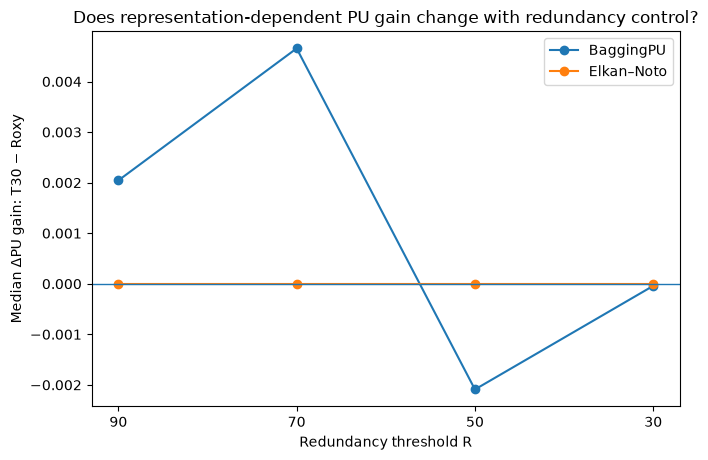

In [11]:
focus = central_by_R[
    central_by_R["contrast"].eq("ESM2-T30 − Roxy")
].copy()

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for method in DEDICATED_METHODS:
    g = (
        focus[focus["method"].eq(method)]
        .assign(
            order=lambda x: x["R"].map(
                {90: 0, 70: 1, 50: 2, 30: 3}
            )
        )
        .sort_values("order")
    )

    ax.plot(
        g["R"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median ΔPU gain: T30 − Roxy")
ax.set_title("Does representation-dependent PU gain change with redundancy control?")
ax.legend()
plt.tight_layout()
plt.show()


# 9. Symmetric view: representation gains inside each PU paradigm


In [12]:
REP_GAIN_KEYS = [
    "task", "R", "S", "method", "algorithm"
]

rep_gain_rows = []

for metric in [PRIMARY, "median_P_percentile_vs_U"]:
    wide = native.pivot_table(
        index=REP_GAIN_KEYS,
        columns="representation",
        values=metric,
        aggfunc="first",
    ).reset_index()

    for rep_a, rep_b in REP_CONTRASTS:
        tmp = wide[REP_GAIN_KEYS].copy()
        tmp["metric"] = metric
        tmp["representation_A"] = rep_a
        tmp["representation_B"] = rep_b
        tmp["value_A"] = wide[rep_a]
        tmp["value_B"] = wide[rep_b]
        tmp["representation_gain_B_minus_A"] = (
            wide[rep_b] - wide[rep_a]
        )
        rep_gain_rows.append(tmp)

representation_gain = pd.concat(
    rep_gain_rows,
    ignore_index=True,
)

rep_gain_summary = (
    representation_gain.groupby(
        [
            "metric", "method",
            "representation_A", "representation_B",
        ]
    )["representation_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

rep_gain_summary["contrast"] = (
    rep_gain_summary["representation_B"].map(REP_LABELS)
    + " − "
    + rep_gain_summary["representation_A"].map(REP_LABELS)
)

display(
    rep_gain_summary[
        rep_gain_summary["metric"].eq(PRIMARY)
    ][
        [
            "method", "contrast",
            "n", "mean", "median", "q25", "q75",
        ]
    ]
)


,method,contrast,n,mean,median,q25,q75
0,baggingpu,ESM2-T30 − ESM2-T6,64,0.077683,0.075929,0.066805,0.087554
1,baggingpu,ESM2-T30 − One-hot,64,0.373486,0.363763,0.313683,0.431676
2,baggingpu,ESM2-T6 − One-hot,64,0.295803,0.288345,0.248276,0.353802
3,baggingpu,ESM2-T30 − Roxy,64,0.217926,0.208786,0.169428,0.258879
4,baggingpu,ESM2-T6 − Roxy,64,0.140243,0.124737,0.090974,0.171077
5,baggingpu,One-hot − Roxy,64,-0.155560,-0.152882,-0.191625,-0.115041
6,elkan_noto,ESM2-T30 − ESM2-T6,64,0.072676,0.072383,0.061444,0.081480
7,elkan_noto,ESM2-T30 − One-hot,64,0.450125,0.412585,0.348788,0.527724
8,elkan_noto,ESM2-T6 − One-hot,64,0.377449,0.339628,0.272169,0.465204
9,elkan_noto,ESM2-T30 − Roxy,64,0.205325,0.212747,0.173620,0.234854


This is the mathematically symmetric reading of the same interaction:

> Does the benefit of T30 over T6/Roxy change when the learner moves from naive P-vs-U to BaggingPU or Elkan–Noto?

If the representation gain is nearly identical across paradigms, representation and PU method are largely separable for known-positive recovery.

If the representation gain changes strongly across paradigms, there is meaningful representation × learning-paradigm coupling.


# 10. How large is paradigm dependence relative to representation dependence?


In [13]:
# Paradigm spread within each task/R/S/representation/algorithm.
method_spread = (
    native.groupby(
        ["task", "R", "S", "representation", "algorithm"]
    )[PRIMARY]
    .agg(
        method_min="min",
        method_max="max",
    )
    .reset_index()
)

method_spread["method_spread"] = (
    method_spread["method_max"]
    - method_spread["method_min"]
)

# Representation spread within each task/R/S/method/algorithm.
representation_spread = (
    native.groupby(
        ["task", "R", "S", "method", "algorithm"]
    )[PRIMARY]
    .agg(
        representation_min="min",
        representation_max="max",
    )
    .reset_index()
)

representation_spread["representation_spread"] = (
    representation_spread["representation_max"]
    - representation_spread["representation_min"]
)

display(
    method_spread.groupby("representation")["method_spread"]
    .agg(
        n="size",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(REPRESENTATIONS)
)

display(
    representation_spread.groupby("method")["representation_spread"]
    .agg(
        n="size",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(METHODS)
)


,n,median,q25,q75
representation,,,,
roxy_48,64,0.007072,0.002875,0.027558
onehot_1024,64,0.117950,0.033260,0.167707
esm2_t6_8m,64,0.006045,0.002065,0.012390
esm2_t30_150m,64,0.005442,0.003093,0.011054


,n,median,q25,q75
method,,,,
naive,64,0.479818,0.351705,0.529877
baggingpu,64,0.363763,0.313683,0.431676
elkan_noto,64,0.412585,0.348788,0.527724


Two separate questions are answered here:

1. **Does a stronger representation reduce sensitivity to PU paradigm?**  
   This is visible if method spread shrinks from Roxy/one-hot toward T30.

2. **Does explicit PU learning reduce sensitivity to representation?**  
   This is visible if representation spread is smaller under BaggingPU/EN than under naive.

Neither quantity is a biological-accuracy estimate. They quantify benchmark dependence on modeling choices.


# 11. Candidate ranking concordance across paradigms


In [14]:
METHOD_CONC_PATH = PU_DIR / "pu_method_score_concordance.tsv"

if not METHOD_CONC_PATH.is_file():
    raise FileNotFoundError(METHOD_CONC_PATH)

method_concordance = pd.read_csv(
    METHOD_CONC_PATH,
    sep="\t",
    low_memory=False,
)

required_conc = {
    "task", "R", "S", "representation", "algorithm",
    "method_A", "method_B", "n_shared_U",
    "spearman", "mae",
    "top_1pct_jaccard", "top_5pct_jaccard",
}
missing = required_conc - set(method_concordance.columns)
if missing:
    raise KeyError(
        f"Method concordance missing columns: {sorted(missing)}"
    )

def normalized_pair(a, b):
    pair = frozenset([str(a), str(b)])
    if pair == frozenset(["naive", "baggingpu"]):
        return "Naive vs BaggingPU"
    if pair == frozenset(["naive", "elkan_noto"]):
        return "Naive vs Elkan–Noto"
    if pair == frozenset(["baggingpu", "elkan_noto"]):
        return "BaggingPU vs Elkan–Noto"
    return f"{a} vs {b}"

method_concordance["pair"] = [
    normalized_pair(a, b)
    for a, b in zip(
        method_concordance["method_A"],
        method_concordance["method_B"],
    )
]

candidate_by_rep = (
    method_concordance.groupby(["pair", "representation"])
    .agg(
        n=("spearman", "size"),
        median_shared_U=("n_shared_U", "median"),
        median_spearman=("spearman", "median"),
        q25_spearman=("spearman", lambda x: x.quantile(0.25)),
        q75_spearman=("spearman", lambda x: x.quantile(0.75)),
        median_top1_fixed=("top_1pct_jaccard", "median"),
        median_top5_fixed=("top_5pct_jaccard", "median"),
        median_MAE=("mae", "median"),
    )
    .reset_index()
)

candidate_by_rep["representation"] = pd.Categorical(
    candidate_by_rep["representation"],
    categories=REPRESENTATIONS,
    ordered=True,
)

display(
    candidate_by_rep.sort_values(
        ["pair", "representation"]
    )
)


,pair,representation,n,median_shared_U,median_spearman,q25_spearman,q75_spearman,median_top1_fixed,median_top5_fixed,median_MAE
3,BaggingPU vs Elkan–Noto,roxy_48,64,38818.5,0.967430,0.907817,0.999531,0.185723,0.686196,0.070629
2,BaggingPU vs Elkan–Noto,onehot_1024,64,38818.5,0.668455,0.481265,0.869648,0.088639,0.353352,0.119884
1,BaggingPU vs Elkan–Noto,esm2_t6_8m,64,38818.5,0.907621,0.851601,0.971770,0.522934,0.700646,0.051380
0,BaggingPU vs Elkan–Noto,esm2_t30_150m,64,38818.5,0.807569,0.762680,0.881562,0.626671,0.529634,0.046249
7,Naive vs BaggingPU,roxy_48,64,38818.5,0.967496,0.907825,0.999653,0.753912,0.811643,0.039297
6,Naive vs BaggingPU,onehot_1024,64,38818.5,0.668640,0.481535,0.869745,0.329825,0.410044,0.169721
5,Naive vs BaggingPU,esm2_t6_8m,64,38818.5,0.907626,0.851601,0.971779,0.675854,0.700646,0.053183
4,Naive vs BaggingPU,esm2_t30_150m,64,38818.5,0.807569,0.762680,0.881564,0.657416,0.529634,0.047135
11,Naive vs Elkan–Noto,roxy_48,64,38818.5,0.999982,0.999942,0.999997,0.201910,1.000000,0.035135
10,Naive vs Elkan–Noto,onehot_1024,64,38818.5,0.999958,0.999902,0.999972,0.121187,1.000000,0.052093


# 12. Tie-aware top-1% and top-5% candidate agreement


In [15]:
TAIL_CONC_PATH = CACHE_DIR / "rq12_pu_tie_aware_tail_concordance.tsv"

if TAIL_CONC_PATH.is_file():
    tie_aware = pd.read_csv(
        TAIL_CONC_PATH,
        sep="\t",
        low_memory=False,
    )
    tie_source = "RQ12 tie-aware cache"
else:
    tie_aware = pd.DataFrame()
    tie_source = "not available"

print("Tie-aware source:", tie_source)

if len(tie_aware):
    required_tie = {
        "task", "R", "S", "representation", "algorithm",
        "tail", "method_A", "method_B",
        "inclusive_jaccard",
        "inclusive_overlap_coefficient",
        "pool_fraction_A", "pool_fraction_B",
        "boundary_tie_fraction_A",
        "boundary_tie_fraction_B",
    }
    missing = required_tie - set(tie_aware.columns)
    if missing:
        raise KeyError(
            f"Tie-aware concordance missing columns: {sorted(missing)}"
        )

    tie_aware["pair"] = [
        normalized_pair(a, b)
        for a, b in zip(
            tie_aware["method_A"],
            tie_aware["method_B"],
        )
    ]

    tie_by_rep = (
        tie_aware.groupby(
            ["pair", "tail", "representation"]
        )
        .agg(
            n=("inclusive_jaccard", "size"),
            median_jaccard=("inclusive_jaccard", "median"),
            median_overlap=(
                "inclusive_overlap_coefficient", "median"
            ),
            median_pool_fraction_A=("pool_fraction_A", "median"),
            median_pool_fraction_B=("pool_fraction_B", "median"),
            median_boundary_tie_A=(
                "boundary_tie_fraction_A", "median"
            ),
            median_boundary_tie_B=(
                "boundary_tie_fraction_B", "median"
            ),
        )
        .reset_index()
    )

    tie_by_rep["representation"] = pd.Categorical(
        tie_by_rep["representation"],
        categories=REPRESENTATIONS,
        ordered=True,
    )

    display(
        tie_by_rep.sort_values(
            ["pair", "tail", "representation"]
        )
    )
else:
    tie_by_rep = pd.DataFrame()
    print(
        "Tie-aware cache unavailable. Fixed-top-k concordance remains available, "
        "but RQ15 should be interpreted conservatively for Elkan–Noto tails."
    )


Tie-aware source: RQ12 tie-aware cache


,pair,tail,representation,n,median_jaccard,median_overlap,median_pool_fraction_A,median_pool_fraction_B,median_boundary_tie_A,median_boundary_tie_B
3,BaggingPU vs Elkan–Noto,top_1pct,roxy_48,64,0.307570,0.990157,0.010012,0.032490,0.0,0.032490
2,BaggingPU vs Elkan–Noto,top_1pct,onehot_1024,64,0.160963,0.829306,0.010012,0.043723,0.0,0.043723
1,BaggingPU vs Elkan–Noto,top_1pct,esm2_t6_8m,64,0.584768,0.891185,0.010012,0.011785,0.0,0.006768
0,BaggingPU vs Elkan–Noto,top_1pct,esm2_t30_150m,64,0.638913,0.804577,0.010012,0.010016,0.0,0.000000
7,BaggingPU vs Elkan–Noto,top_5pct,roxy_48,64,0.717565,0.900908,0.050015,0.050020,0.0,0.000000
6,BaggingPU vs Elkan–Noto,top_5pct,onehot_1024,64,0.402359,0.597301,0.050015,0.050027,0.0,0.000000
5,BaggingPU vs Elkan–Noto,top_5pct,esm2_t6_8m,64,0.700646,0.823303,0.050015,0.050015,0.0,0.000000
4,BaggingPU vs Elkan–Noto,top_5pct,esm2_t30_150m,64,0.529927,0.692881,0.050015,0.050015,0.0,0.000000
11,Naive vs BaggingPU,top_1pct,roxy_48,64,0.753912,0.858510,0.010012,0.010012,0.0,0.000000
10,Naive vs BaggingPU,top_1pct,onehot_1024,64,0.329825,0.496032,0.010012,0.010012,0.0,0.000000


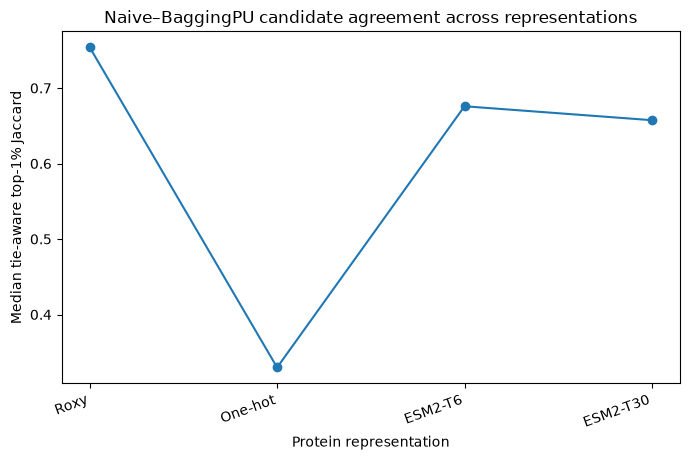

In [16]:
if len(tie_by_rep):
    focus_tail = tie_by_rep[
        tie_by_rep["pair"].eq("Naive vs BaggingPU")
        & tie_by_rep["tail"].eq("top_1pct")
    ].sort_values("representation")

    fig, ax = plt.subplots(figsize=(7.0, 4.7))
    ax.plot(
        [REP_LABELS[str(x)] for x in focus_tail["representation"]],
        focus_tail["median_jaccard"],
        marker="o",
    )
    ax.set_xlabel("Protein representation")
    ax.set_ylabel("Median tie-aware top-1% Jaccard")
    ax.set_title("Naive–BaggingPU candidate agreement across representations")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()


# 13. Does T30 stabilize paradigm-dependent candidate rankings?


In [17]:
candidate_interaction_rows = []

# Global score-order agreement.
for pair, grp in method_concordance.groupby("pair"):
    wide = grp.pivot_table(
        index=["task", "R", "S", "algorithm"],
        columns="representation",
        values="spearman",
        aggfunc="first",
    ).reset_index()

    for rep_a, rep_b in [
        ("roxy_48", "esm2_t30_150m"),
        ("esm2_t6_8m", "esm2_t30_150m"),
    ]:
        tmp = wide[
            ["task", "R", "S", "algorithm"]
        ].copy()
        tmp["pair"] = pair
        tmp["diagnostic"] = "U_score_spearman"
        tmp["representation_A"] = rep_a
        tmp["representation_B"] = rep_b
        tmp["value_A"] = wide[rep_a]
        tmp["value_B"] = wide[rep_b]
        tmp["delta_B_minus_A"] = wide[rep_b] - wide[rep_a]
        candidate_interaction_rows.append(tmp)

# Tie-aware candidate-tail agreement.
if len(tie_aware):
    for (pair, tail), grp in tie_aware.groupby(["pair", "tail"]):
        wide = grp.pivot_table(
            index=["task", "R", "S", "algorithm"],
            columns="representation",
            values="inclusive_jaccard",
            aggfunc="first",
        ).reset_index()

        for rep_a, rep_b in [
            ("roxy_48", "esm2_t30_150m"),
            ("esm2_t6_8m", "esm2_t30_150m"),
        ]:
            tmp = wide[
                ["task", "R", "S", "algorithm"]
            ].copy()
            tmp["pair"] = pair
            tmp["diagnostic"] = f"{tail}_tie_aware_jaccard"
            tmp["representation_A"] = rep_a
            tmp["representation_B"] = rep_b
            tmp["value_A"] = wide[rep_a]
            tmp["value_B"] = wide[rep_b]
            tmp["delta_B_minus_A"] = wide[rep_b] - wide[rep_a]
            candidate_interaction_rows.append(tmp)

candidate_rep_interaction = pd.concat(
    candidate_interaction_rows,
    ignore_index=True,
)

candidate_rep_interaction["contrast"] = (
    candidate_rep_interaction["representation_B"].map(REP_LABELS)
    + " − "
    + candidate_rep_interaction["representation_A"].map(REP_LABELS)
)

candidate_rep_interaction_summary = (
    candidate_rep_interaction.groupby(
        ["pair", "diagnostic", "contrast"]
    )["delta_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reset_index()
)

display(candidate_rep_interaction_summary)


,pair,diagnostic,contrast,n,mean,median,q25,q75,fraction_positive,fraction_negative
0,BaggingPU vs Elkan–Noto,U_score_spearman,ESM2-T30 − ESM2-T6,64,-0.086710,-8.265095e-02,-1.054192e-01,-0.067898,0.000000,1.00000
1,BaggingPU vs Elkan–Noto,U_score_spearman,ESM2-T30 − Roxy,64,-0.132597,-1.229090e-01,-1.624981e-01,-0.105769,0.000000,1.00000
2,BaggingPU vs Elkan–Noto,top_1pct_tie_aware_jaccard,ESM2-T30 − ESM2-T6,64,0.087871,5.974471e-02,2.018345e-02,0.112387,0.828125,0.12500
3,BaggingPU vs Elkan–Noto,top_1pct_tie_aware_jaccard,ESM2-T30 − Roxy,64,0.276184,2.684594e-01,1.397718e-01,0.396425,0.968750,0.03125
4,BaggingPU vs Elkan–Noto,top_5pct_tie_aware_jaccard,ESM2-T30 − ESM2-T6,64,-0.153631,-1.356406e-01,-2.376421e-01,-0.089322,0.000000,1.00000
5,BaggingPU vs Elkan–Noto,top_5pct_tie_aware_jaccard,ESM2-T30 − Roxy,64,-0.216108,-1.742346e-01,-2.777766e-01,-0.132372,0.000000,1.00000
6,Naive vs BaggingPU,U_score_spearman,ESM2-T30 − ESM2-T6,64,-0.086713,-8.265106e-02,-1.054214e-01,-0.067898,0.000000,1.00000
7,Naive vs BaggingPU,U_score_spearman,ESM2-T30 − Roxy,64,-0.132639,-1.229799e-01,-1.625061e-01,-0.105879,0.000000,1.00000
8,Naive vs BaggingPU,top_1pct_tie_aware_jaccard,ESM2-T30 − ESM2-T6,64,-0.062501,-5.062461e-02,-1.659161e-01,0.036741,0.359375,0.59375
9,Naive vs BaggingPU,top_1pct_tie_aware_jaccard,ESM2-T30 − Roxy,64,-0.125300,-9.863240e-02,-2.904514e-01,0.018688,0.312500,0.68750


For agreement metrics:

- positive `T30 − T6` or `T30 − Roxy` → stronger representation makes the two paradigms **more similar / more stable** in their ranking of U;
- negative → stronger representation allows the paradigms to **diverge more strongly** in candidate prioritization.

This is independent of whether known-positive U95 recovery improves.


# 14. Representation-conditioned BaggingPU internal stability


In [18]:
BAG_PATH = CACHE_DIR / "rq12_bagging_stability.tsv"

if BAG_PATH.is_file():
    bag = pd.read_csv(
        BAG_PATH,
        sep="\t",
        low_memory=False,
    )
else:
    stage_bag = PU_DIR / "pu_bagging_stability_summary.tsv"
    bag = (
        pd.read_csv(stage_bag, sep="\t", low_memory=False)
        if stage_bag.is_file()
        else pd.DataFrame()
    )

if len(bag):
    if "representation" not in bag.columns:
        bag = bag.merge(
            registry[
                [
                    "experiment_id", "task", "R", "S",
                    "representation", "algorithm",
                ]
            ],
            on="experiment_id",
            how="left",
            validate="one_to_one",
        )

    bag_var_cols = [
        c for c in [
            "median_test_score_std",
            "mean_test_score_std",
        ]
        if c in bag.columns
    ]

    if bag_var_cols:
        bag_stability_rows = []

        for c in bag_var_cols:
            tmp = (
                bag.groupby("representation")[c]
                .agg(
                    n="size",
                    mean="mean",
                    median="median",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                )
                .reset_index()
            )
            tmp["variability_metric"] = c
            bag_stability_rows.append(tmp)

        bag_stability_by_rep = pd.concat(
            bag_stability_rows,
            ignore_index=True,
        )

        bag_stability_by_rep["representation"] = pd.Categorical(
            bag_stability_by_rep["representation"],
            categories=REPRESENTATIONS,
            ordered=True,
        )

        display(
            bag_stability_by_rep.sort_values(
                ["variability_metric", "representation"]
            )
        )

        bag_pair_rows = []

        for c in bag_var_cols:
            wide = bag.pivot_table(
                index=["task", "R", "S", "algorithm"],
                columns="representation",
                values=c,
                aggfunc="first",
            ).reset_index()

            for rep_a, rep_b in [
                ("roxy_48", "esm2_t30_150m"),
                ("esm2_t6_8m", "esm2_t30_150m"),
            ]:
                tmp = wide[
                    ["task", "R", "S", "algorithm"]
                ].copy()
                tmp["variability_metric"] = c
                tmp["representation_A"] = rep_a
                tmp["representation_B"] = rep_b
                tmp["delta_variability_B_minus_A"] = (
                    wide[rep_b] - wide[rep_a]
                )
                bag_pair_rows.append(tmp)

        bag_stability_contrasts = pd.concat(
            bag_pair_rows,
            ignore_index=True,
        )

        display(
            bag_stability_contrasts.groupby(
                [
                    "variability_metric",
                    "representation_A",
                    "representation_B",
                ]
            )["delta_variability_B_minus_A"]
            .agg(
                n="size",
                mean="mean",
                median="median",
                q25=lambda x: x.quantile(0.25),
                q75=lambda x: x.quantile(0.75),
                fraction_lower_variability=lambda x: (x < 0).mean(),
            )
            .reset_index()
        )
    else:
        bag_stability_by_rep = pd.DataFrame()
        bag_stability_contrasts = pd.DataFrame()
        print("Bagging stability table contains no score-variability columns.")
else:
    bag_stability_by_rep = pd.DataFrame()
    bag_stability_contrasts = pd.DataFrame()
    print("BaggingPU stability cache not available.")


,representation,n,mean,median,q25,q75,variability_metric
7,roxy_48,64,0.034189,0.031248,0.018492,0.048791,mean_test_score_std
6,onehot_1024,64,0.089951,0.087433,0.069767,0.104010,mean_test_score_std
5,esm2_t6_8m,64,0.050431,0.044745,0.038146,0.059929,mean_test_score_std
4,esm2_t30_150m,64,0.047847,0.041254,0.020591,0.070611,mean_test_score_std
3,roxy_48,64,0.016473,0.015792,0.012064,0.020720,median_test_score_std
2,onehot_1024,64,0.060289,0.057556,0.045831,0.073251,median_test_score_std
1,esm2_t6_8m,64,0.021531,0.015148,0.007364,0.032949,median_test_score_std
0,esm2_t30_150m,64,0.013934,0.006841,0.002104,0.022168,median_test_score_std


,variability_metric,representation_A,representation_B,n,mean,median,q25,q75,fraction_lower_variability
0,mean_test_score_std,esm2_t6_8m,esm2_t30_150m,64,-0.002583,-0.004697,-0.016252,0.009193,0.500000
1,mean_test_score_std,roxy_48,esm2_t30_150m,64,0.013658,0.005847,-0.026971,0.052504,0.500000
2,median_test_score_std,esm2_t6_8m,esm2_t30_150m,64,-0.007598,-0.006908,-0.009995,-0.004429,0.984375
3,median_test_score_std,roxy_48,esm2_t30_150m,64,-0.002539,-0.003771,-0.013510,0.005768,0.640625


For BaggingPU variability, **negative** `T30 − T6` or `T30 − Roxy` means that the stronger representation produces more internally stable scores across temporary-negative bags.


# 15. Secondary RQ14 bridge: representation × paradigm inside broad U


In [19]:
RQ14_BROAD_PATH = CACHE_DIR / "rq14_broad_U_state_score_composition.tsv"

if RQ14_BROAD_PATH.is_file():
    broad_u = pd.read_csv(
        RQ14_BROAD_PATH,
        sep="\t",
        low_memory=False,
    )
else:
    broad_u = pd.DataFrame()

if len(broad_u):
    required_broad = {
        "R", "S", "representation", "method", "algorithm",
        "U_other_top5_enrichment",
        "fraction_other_above_explicit_U95",
        "median_other_percentile_vs_explicit",
    }
    missing = required_broad - set(broad_u.columns)
    if missing:
        raise KeyError(
            f"RQ14 broad-U cache missing: {sorted(missing)}"
        )

    broad_rep_method = (
        broad_u.groupby(["representation", "method"])
        .agg(
            n=("U_other_top5_enrichment", "size"),
            median_U_other_top5_enrichment=(
                "U_other_top5_enrichment", "median"
            ),
            median_other_above_explicit_U95=(
                "fraction_other_above_explicit_U95", "median"
            ),
            median_other_percentile_vs_explicit=(
                "median_other_percentile_vs_explicit", "median"
            ),
        )
        .reset_index()
    )

    broad_rep_method["representation"] = pd.Categorical(
        broad_rep_method["representation"],
        categories=REPRESENTATIONS,
        ordered=True,
    )

    display(
        broad_rep_method.sort_values(
            ["representation", "method"]
        )
    )

    broad_enrich_gain_rows = []

    wide = broad_u.pivot_table(
        index=["R", "S", "representation", "algorithm"],
        columns="method",
        values="U_other_top5_enrichment",
        aggfunc="first",
    ).reset_index()

    for method in DEDICATED_METHODS:
        tmp = wide[
            ["R", "S", "representation", "algorithm"]
        ].copy()
        tmp["method"] = method
        tmp["enrichment_gain_vs_naive"] = (
            wide[method] - wide["naive"]
        )
        broad_enrich_gain_rows.append(tmp)

    broad_enrichment_gain = pd.concat(
        broad_enrich_gain_rows,
        ignore_index=True,
    )

    display(
        broad_enrichment_gain.groupby(
            ["method", "representation"]
        )["enrichment_gain_vs_naive"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )
else:
    broad_rep_method = pd.DataFrame()
    broad_enrichment_gain = pd.DataFrame()
    print(
        "RQ14 broad-U cache not found. "
        "The main RQ15 analysis remains complete; broad-U enrichment bridge skipped."
    )


,representation,method,n,median_U_other_top5_enrichment,median_other_above_explicit_U95,median_other_percentile_vs_explicit
9,roxy_48,baggingpu,32,2.121370,0.172908,0.767361
10,roxy_48,elkan_noto,32,2.065792,0.160952,0.757103
11,roxy_48,naive,32,2.113821,0.160952,0.757103
6,onehot_1024,baggingpu,32,2.137963,0.179229,0.785003
7,onehot_1024,elkan_noto,32,1.763881,0.125912,0.608189
8,onehot_1024,naive,32,1.780750,0.125912,0.608189
3,esm2_t6_8m,baggingpu,32,1.835808,0.129226,0.666974
4,esm2_t6_8m,elkan_noto,32,1.772455,0.117657,0.615769
5,esm2_t6_8m,naive,32,1.772455,0.117657,0.615769
0,esm2_t30_150m,baggingpu,32,2.049574,0.146244,0.684309


,method,representation,n,mean,median,q25,q75
0,baggingpu,esm2_t30_150m,32,0.186332,0.205962,0.101369,0.242356
1,baggingpu,esm2_t6_8m,32,0.098624,0.072229,0.027573,0.156498
2,baggingpu,onehot_1024,32,0.338441,0.245286,0.116711,0.497796
3,baggingpu,roxy_48,32,0.025981,0.014423,0.001978,0.033465
4,elkan_noto,esm2_t30_150m,32,0.000000,0.000000,0.000000,0.000000
5,elkan_noto,esm2_t6_8m,32,0.000000,0.000000,0.000000,0.000000
6,elkan_noto,onehot_1024,32,-0.027347,-0.027034,-0.054494,0.000000
7,elkan_noto,roxy_48,32,-0.028706,-0.007803,-0.054622,0.000000


This section is deliberately secondary.

A positive BaggingPU-minus-naive enrichment effect under T30 would suggest that a richer representation helps the PU learner preferentially surface the additional unresolved proteins found in RQ14.

It must **not** be interpreted as evidence that those proteins are true positives.


# 16. Consistency across conservative and broad U universes


In [20]:
gain_task_rep = (
    method_gain.groupby(
        ["task", "method", "representation"]
    )["gain_vs_naive"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_practical_tie=lambda x: (
            x.abs() <= PRACTICAL_TIE
        ).mean(),
    )
    .reset_index()
)

display(gain_task_rep)

universe_interaction = (
    central_interactions.groupby(
        ["task", "method", "contrast"]
    )["delta_PU_gain_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(universe_interaction)


,task,method,representation,n,mean,median,q25,q75,fraction_practical_tie
0,pu_broad,baggingpu,esm2_t30_150m,32,0.002431,0.000456,-0.002459,0.004625,0.93750
1,pu_broad,baggingpu,esm2_t6_8m,32,-0.002562,-0.001605,-0.010169,0.003039,0.84375
2,pu_broad,baggingpu,onehot_1024,32,0.096567,0.093082,0.024388,0.160772,0.21875
3,pu_broad,baggingpu,roxy_48,32,0.001275,0.000700,-0.003065,0.004103,0.93750
4,pu_broad,elkan_noto,esm2_t30_150m,32,0.000000,0.000000,0.000000,0.000000,1.00000
5,pu_broad,elkan_noto,esm2_t6_8m,32,0.000000,0.000000,0.000000,0.000000,1.00000
6,pu_broad,elkan_noto,onehot_1024,32,0.034169,0.020027,0.000000,0.058941,0.50000
7,pu_broad,elkan_noto,roxy_48,32,0.023559,0.014374,0.000000,0.048100,0.50000
8,pu_conservative,baggingpu,esm2_t30_150m,32,0.000337,0.000344,-0.007318,0.007558,0.96875
9,pu_conservative,baggingpu,esm2_t6_8m,32,-0.004684,-0.004507,-0.011508,0.001134,0.90625


,task,method,contrast,n,mean,median,q25,q75
0,pu_broad,baggingpu,ESM2-T30 − ESM2-T6,32,0.004993,0.003314,-8.416930e-04,0.009311
1,pu_broad,baggingpu,ESM2-T30 − Roxy,32,0.001156,0.002006,-6.135162e-03,0.008336
2,pu_broad,elkan_noto,ESM2-T30 − ESM2-T6,32,0.000000,0.000000,0.000000e+00,0.000000
3,pu_broad,elkan_noto,ESM2-T30 − Roxy,32,-0.023559,-0.014374,-4.810050e-02,0.000000
4,pu_conservative,baggingpu,ESM2-T30 − ESM2-T6,32,0.005021,0.004915,8.326673e-17,0.008791
5,pu_conservative,baggingpu,ESM2-T30 − Roxy,32,0.000485,0.001578,-6.940857e-03,0.009680
6,pu_conservative,elkan_noto,ESM2-T30 − ESM2-T6,32,0.000000,0.000000,0.000000e+00,0.000000
7,pu_conservative,elkan_noto,ESM2-T30 − Roxy,32,0.000000,0.000000,0.000000e+00,0.000000


# 17. Cross-metric sensitivity


In [21]:
cross_metric_gain_rows = []

for metric in RECOGNITION_METRICS:
    wide = native.pivot_table(
        index=GAIN_KEYS,
        columns="method",
        values=metric,
        aggfunc="first",
    ).reset_index()

    for method in DEDICATED_METHODS:
        tmp = wide[GAIN_KEYS].copy()
        tmp["metric"] = metric
        tmp["method"] = method
        tmp["gain_vs_naive"] = (
            wide[method] - wide["naive"]
        )
        cross_metric_gain_rows.append(tmp)

cross_metric_gain = pd.concat(
    cross_metric_gain_rows,
    ignore_index=True,
)

cross_metric_summary = (
    cross_metric_gain.groupby(
        ["metric", "method", "representation"]
    )["gain_vs_naive"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(cross_metric_summary)


,metric,method,representation,n,mean,median,q25,q75
0,fraction_P_above_U90,baggingpu,esm2_t30_150m,64,0.001112,0.000000,-0.004625,0.006167
1,fraction_P_above_U90,baggingpu,esm2_t6_8m,64,-0.001718,-0.001381,-0.005871,0.002042
2,fraction_P_above_U90,baggingpu,onehot_1024,64,0.128328,0.110984,0.015688,0.235312
3,fraction_P_above_U90,baggingpu,roxy_48,64,0.002439,0.001977,-0.001394,0.005698
4,fraction_P_above_U90,elkan_noto,esm2_t30_150m,64,0.000000,0.000000,0.000000,0.000000
5,fraction_P_above_U90,elkan_noto,esm2_t6_8m,64,0.000000,0.000000,0.000000,0.000000
6,fraction_P_above_U90,elkan_noto,onehot_1024,64,0.000000,0.000000,0.000000,0.000000
7,fraction_P_above_U90,elkan_noto,roxy_48,64,0.000000,0.000000,0.000000,0.000000
8,fraction_P_above_U95,baggingpu,esm2_t30_150m,64,0.001384,0.000344,-0.005438,0.005313
9,fraction_P_above_U95,baggingpu,esm2_t6_8m,64,-0.003623,-0.002757,-0.010683,0.001997


U99 and especially Elkan–Noto must be interpreted with the tie/clipping audit from RQ12.

The purpose of this table is directional robustness: whether a representation-dependent method effect seen at U95 is also reflected in P-percentile or U90 behavior.


# 18. Compact RQ15 evidence table


In [22]:
evidence_rows = []

for method in DEDICATED_METHODS:
    for rep in REPRESENTATIONS:
        g = method_gain[
            method_gain["method"].eq(method)
            & method_gain["representation"].eq(rep)
        ]["gain_vs_naive"]

        cand = candidate_by_rep[
            candidate_by_rep["representation"].astype(str).eq(rep)
            & candidate_by_rep["pair"].eq(
                "Naive vs BaggingPU"
                if method == "baggingpu"
                else "Naive vs Elkan–Noto"
            )
        ]

        row = {
            "method": method,
            "representation": rep,
            "median_U95_gain_vs_naive": g.median(),
            "fraction_U95_practical_tie": (
                g.abs() <= PRACTICAL_TIE
            ).mean(),
            "median_method_pair_U_spearman": (
                cand["median_spearman"].iloc[0]
                if len(cand)
                else np.nan
            ),
            "median_fixed_top1_jaccard": (
                cand["median_top1_fixed"].iloc[0]
                if len(cand)
                else np.nan
            ),
            "median_fixed_top5_jaccard": (
                cand["median_top5_fixed"].iloc[0]
                if len(cand)
                else np.nan
            ),
        }

        if len(tie_by_rep):
            pair_name = (
                "Naive vs BaggingPU"
                if method == "baggingpu"
                else "Naive vs Elkan–Noto"
            )

            t1 = tie_by_rep[
                tie_by_rep["pair"].eq(pair_name)
                & tie_by_rep["tail"].eq("top_1pct")
                & tie_by_rep["representation"].astype(str).eq(rep)
            ]

            t5 = tie_by_rep[
                tie_by_rep["pair"].eq(pair_name)
                & tie_by_rep["tail"].eq("top_5pct")
                & tie_by_rep["representation"].astype(str).eq(rep)
            ]

            row["median_tieaware_top1_jaccard"] = (
                t1["median_jaccard"].iloc[0]
                if len(t1)
                else np.nan
            )
            row["median_tieaware_top5_jaccard"] = (
                t5["median_jaccard"].iloc[0]
                if len(t5)
                else np.nan
            )
        else:
            row["median_tieaware_top1_jaccard"] = np.nan
            row["median_tieaware_top5_jaccard"] = np.nan

        evidence_rows.append(row)

rq15_evidence = pd.DataFrame(evidence_rows)
display(rq15_evidence)


,method,representation,median_U95_gain_vs_naive,fraction_U95_practical_tie,median_method_pair_U_spearman,median_fixed_top1_jaccard,median_fixed_top5_jaccard,median_tieaware_top1_jaccard,median_tieaware_top5_jaccard
0,baggingpu,roxy_48,0.000000,0.953125,0.967496,0.753912,0.811643,0.753912,0.811643
1,baggingpu,onehot_1024,0.093082,0.265625,0.668640,0.329825,0.410044,0.329825,0.410044
2,baggingpu,esm2_t6_8m,-0.002757,0.875000,0.907626,0.675854,0.700646,0.675854,0.700646
3,baggingpu,esm2_t30_150m,0.000344,0.953125,0.807569,0.657416,0.529634,0.657416,0.529927
4,elkan_noto,roxy_48,0.000000,0.750000,0.999982,0.201910,1.000000,0.312151,1.000000
5,elkan_noto,onehot_1024,0.000000,0.750000,0.999958,0.121187,1.000000,0.228979,1.000000
6,elkan_noto,esm2_t6_8m,0.000000,1.000000,0.999999,0.790698,1.000000,0.869565,1.000000
7,elkan_noto,esm2_t30_150m,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# 19. RQ15 synthesis questions


After execution, RQ15 should answer:

1. Does BaggingPU gain over naive differ across Roxy, one-hot, T6 and T30?
2. Does Elkan–Noto U95 gain differ across representations, after retaining the RQ12 tie/clipping interpretation?
3. Does `T30 − T6` make dedicated PU more useful, less useful, or essentially unchanged?
4. Does `T30 − Roxy` tell the same story?
5. Is the interaction consistent across conservative and broad U universes?
6. Is the interaction consistent across LR and XGB?
7. Does redundancy control R amplify or attenuate representation-dependent PU gain?
8. Does homology separation S amplify or attenuate it?
9. Symmetrically, is the representation gain itself different under naive, BaggingPU and Elkan–Noto?
10. Does stronger representation reduce the overall spread among learning paradigms?
11. Does explicit PU reduce the spread among representations?
12. Does T30 increase or decrease naive–BaggingPU global U-ranking agreement?
13. Does T30 increase or decrease tie-aware top-1% candidate overlap between naive and BaggingPU?
14. Does T30 increase or decrease top-5% overlap?
15. Is Elkan–Noto rank-equivalent to naive across all representations, or does any representation break that pattern?
16. Does BaggingPU internal score variability decrease under stronger representations?
17. Within broad U, does BaggingPU preferentially enrich `U_other_unresolved` more strongly under some representations?
18. Do recognition and discovery tell the same representation × paradigm story, or different ones?

The desired result is **not**:

> “T30 + method X is the best model.”

The useful result is a mechanistic description of whether representation and uncertainty-aware learning are:

- largely separable;
- substitutive;
- synergistic for known-positive recovery;
- or coupled mainly through candidate reprioritization rather than recovery.


## Manuscript-level conceptual targets

If strong representations reduce PU-method gain and increase candidate agreement:

> **As protein representations become more informative, the marginal effect of the learning paradigm decreases, suggesting that representation quality can absorb part of the uncertainty-handling burden otherwise delegated to the PU algorithm.**

If strong representations increase BaggingPU gain or candidate-tail divergence:

> **Richer protein representations expose structure within the unlabeled universe that dedicated PU learning can exploit, making uncertainty-aware learning increasingly consequential as representation quality improves.**

If recovery interaction is weak but candidate interaction is strong:

> **Protein representation and PU paradigm are largely separable for recovery of known positives but interact strongly in the discovery space, where representation quality determines how much candidate prioritization changes under uncertainty-aware learning.**

That third outcome would align particularly well with RQ12 and RQ14.


# 20. Export RQ15 cache tables


In [23]:
PATHS = {
    CACHE_DIR / "rq15_recognition_representation_x_method.tsv":
        recognition_summary,
    CACHE_DIR / "rq15_PU_gain_by_representation.tsv":
        method_gain,
    CACHE_DIR / "rq15_PU_gain_representation_summary.tsv":
        gain_by_rep,
    CACHE_DIR / "rq15_representation_x_method_interactions.tsv":
        rep_x_method_interaction,
    CACHE_DIR / "rq15_representation_x_method_interaction_summary.tsv":
        interaction_summary,
    CACHE_DIR / "rq15_central_T30_interactions.tsv":
        central_interactions,
    CACHE_DIR / "rq15_representation_gains_by_method.tsv":
        representation_gain,
    CACHE_DIR / "rq15_method_spread_by_representation.tsv":
        method_spread,
    CACHE_DIR / "rq15_representation_spread_by_method.tsv":
        representation_spread,
    CACHE_DIR / "rq15_candidate_concordance_by_representation.tsv":
        candidate_by_rep,
    CACHE_DIR / "rq15_candidate_representation_interactions.tsv":
        candidate_rep_interaction,
    CACHE_DIR / "rq15_candidate_representation_interaction_summary.tsv":
        candidate_rep_interaction_summary,
    CACHE_DIR / "rq15_cross_metric_gain.tsv":
        cross_metric_gain,
    CACHE_DIR / "rq15_evidence_summary.tsv":
        rq15_evidence,
}

if len(tie_by_rep):
    PATHS[
        CACHE_DIR / "rq15_tieaware_candidate_concordance_by_representation.tsv"
    ] = tie_by_rep

if len(bag_stability_by_rep):
    PATHS[
        CACHE_DIR / "rq15_bagging_stability_by_representation.tsv"
    ] = bag_stability_by_rep
    PATHS[
        CACHE_DIR / "rq15_bagging_stability_representation_contrasts.tsv"
    ] = bag_stability_contrasts

if len(broad_rep_method):
    PATHS[
        CACHE_DIR / "rq15_broadU_representation_x_method.tsv"
    ] = broad_rep_method
    PATHS[
        CACHE_DIR / "rq15_broadU_enrichment_gain_vs_naive.tsv"
    ] = broad_enrichment_gain

for path, frame in PATHS.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved RQ15 cache tables:")
for path in PATHS:
    print(" ", path)


Saved RQ15 cache tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_recognition_representation_x_method.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_PU_gain_by_representation.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_PU_gain_representation_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_representation_x_method_interactions.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_representation_x_method_interaction_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq15_central_T30_interactions.tsv
  /home/david/Desktop/colabs/int

## Final interpretation guardrails

Before freezing RQ15:

- U95 is the primary recognition diagnostic.
- EN U99 is not evidence of superior ranking without strict-U99/tie context.
- Candidate agreement must prioritize tie-aware top-1% and top-5% where available.
- A reduction in method spread does not imply improved biological accuracy.
- A large BaggingPU candidate reordering does not imply that reordered U proteins are positives.
- Representation × method effects across R/S are matched-factor contrasts, not finite-test causal inference.
- Broad-U `U_other_unresolved` enrichment is candidate prioritization, not prevalence estimation.
- Do not collapse recognition and discovery into one winner.
